# Figure 7 — β-VAE Disentanglement Reproduction

Run the **two plotting cells in order**. Reads the official local dSprites dataset in `data/` and the **matched seed-42, 30,000-step** inference checkpoints under `results/seed42/`; figures display **inline**. No training, data downloads, image/PDF exports, or figure directories are created by this notebook. The dataset loader may generate its normal image cache on first use.

Figure 7A compares β-VAE (**β = 4**) with Figure 7B's standard VAE (**β = 1**). Position heatmaps, scale/rotation responses, and five decoded traversals are calculated from the actual trained models. Latents are ordered by **ascending average posterior variance**. Both panels use the **same response scales** and the original rainbow-style position colormap. The factor-response diagnostics are descriptive, not formal disentanglement scores.

## Figure 7A — β-VAE (β = 4)

Full-dataset conditional encoder means for 32 × 32 positions, six scales, and 40 orientations for each shape. The bottom five image rows vary **one model latent** through +3, +1.5, 0, −1.5, −3 while other latents stay fixed to the encoder mean of the same reference image. The selected six columns contain five smallest posterior-variance latents and one high-variance comparison. Both models are evaluated first to obtain common plotting limits.

Project: C:\Users\ASUS\Documents\GitHub\advanced-ml-paper-reproductions\paper3-beta-vae | Device: cpu | Eval batch size: 512


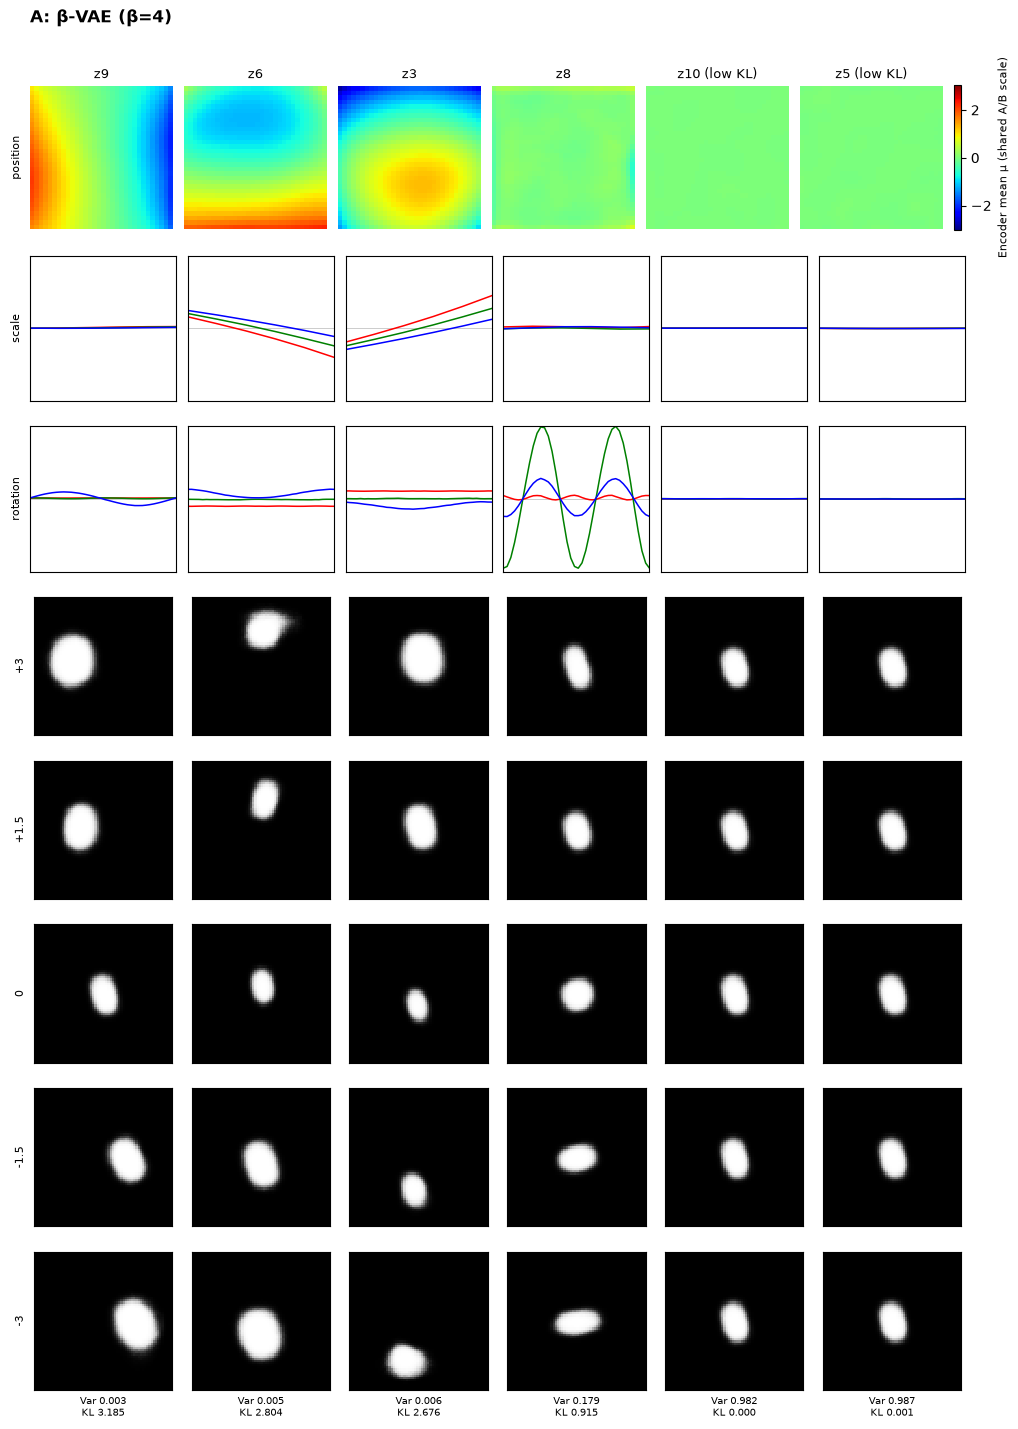

Figure 7A: β=4, seed=42, 30,000 steps; columns z: [9, 6, 3, 8, 10, 5]
Recon BCE/image: 86.063 | KL/image: 9.598


In [2]:
from pathlib import Path
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

# Accept launching the notebook from either paper3-beta-vae/ or its notebooks/ subfolder.
_here = Path.cwd().resolve()
PROJECT = next((p for p in (_here, _here.parent) if (p / 'src' / 'visualize.py').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Open this notebook from paper3-beta-vae/ or paper3-beta-vae/notebooks/.')
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from src.data import DSprites
from src.visualize import data_for_panel, shared_limits, draw_panel, report

DATA = PROJECT / 'data' / 'dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
RUNS = PROJECT / 'results' / 'seed42'
for path in (DATA, RUNS / 'beta4' / 'model.pt', RUNS / 'beta1' / 'model.pt'):
    if not path.is_file():
        raise FileNotFoundError(f'Missing required local file: {path}')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EVAL_BATCH_SIZE = 512 if DEVICE.type == 'cpu' else 2048
print(f'Project: {PROJECT} | Device: {DEVICE} | Eval batch size: {EVAL_BATCH_SIZE}')

# One complete evaluation per model. No random or paper-derived response values.
ds = DSprites(DATA)
A = data_for_panel(RUNS / 'beta4' / 'model.pt', ds, DEVICE, EVAL_BATCH_SIZE)
B = data_for_panel(RUNS / 'beta1' / 'model.pt', ds, DEVICE, EVAL_BATCH_SIZE)
for name, panel, beta in (('7A', A, 4), ('7B', B, 1)):
    ckpt = panel['meta']
    assert float(ckpt['beta']) == beta and int(ckpt['seed']) == 42 and int(ckpt['step']) == 30000, (name, ckpt)
LIMITS = shared_limits([A, B])

# Keep figures in memory; never save a rendered PNG.
def show_panel(panel, label):
    fig, axes = plt.subplots(8, 6, figsize=(11, 15),
        gridspec_kw={'height_ratios': [1.05, 1.05, 1.05, 1, 1, 1, 1, 1]})
    colored = draw_panel(panel, axes, label, LIMITS)
    fig.subplots_adjust(wspace=.08, hspace=.18, left=.08, right=.93, top=.95, bottom=.08)
    bar = fig.colorbar(colored, ax=list(axes[0]), fraction=.012, pad=.012)
    bar.set_label('Encoder mean μ (shared A/B scale)', fontsize=8)
    display(fig)
    plt.close(fig)

show_panel(A, 'A')
print('Figure 7A: β=4, seed=42, 30,000 steps; columns z:', [j+1 for j in A['selected']])
print('Recon BCE/image:', round(A['diagnostics']['bce_per_image'], 3),
      '| KL/image:', round(A['diagnostics']['kl_per_image'], 3))

## Figure 7B — Standard VAE (β = 1)

Uses the **same seed, initialization policy, data, training duration, reference-image factors, and response scales** as 7A. Lower KL weighting often improves reconstructions while allowing different factor entanglement. The plots are results, not a predetermined claim that either model must be more disentangled.

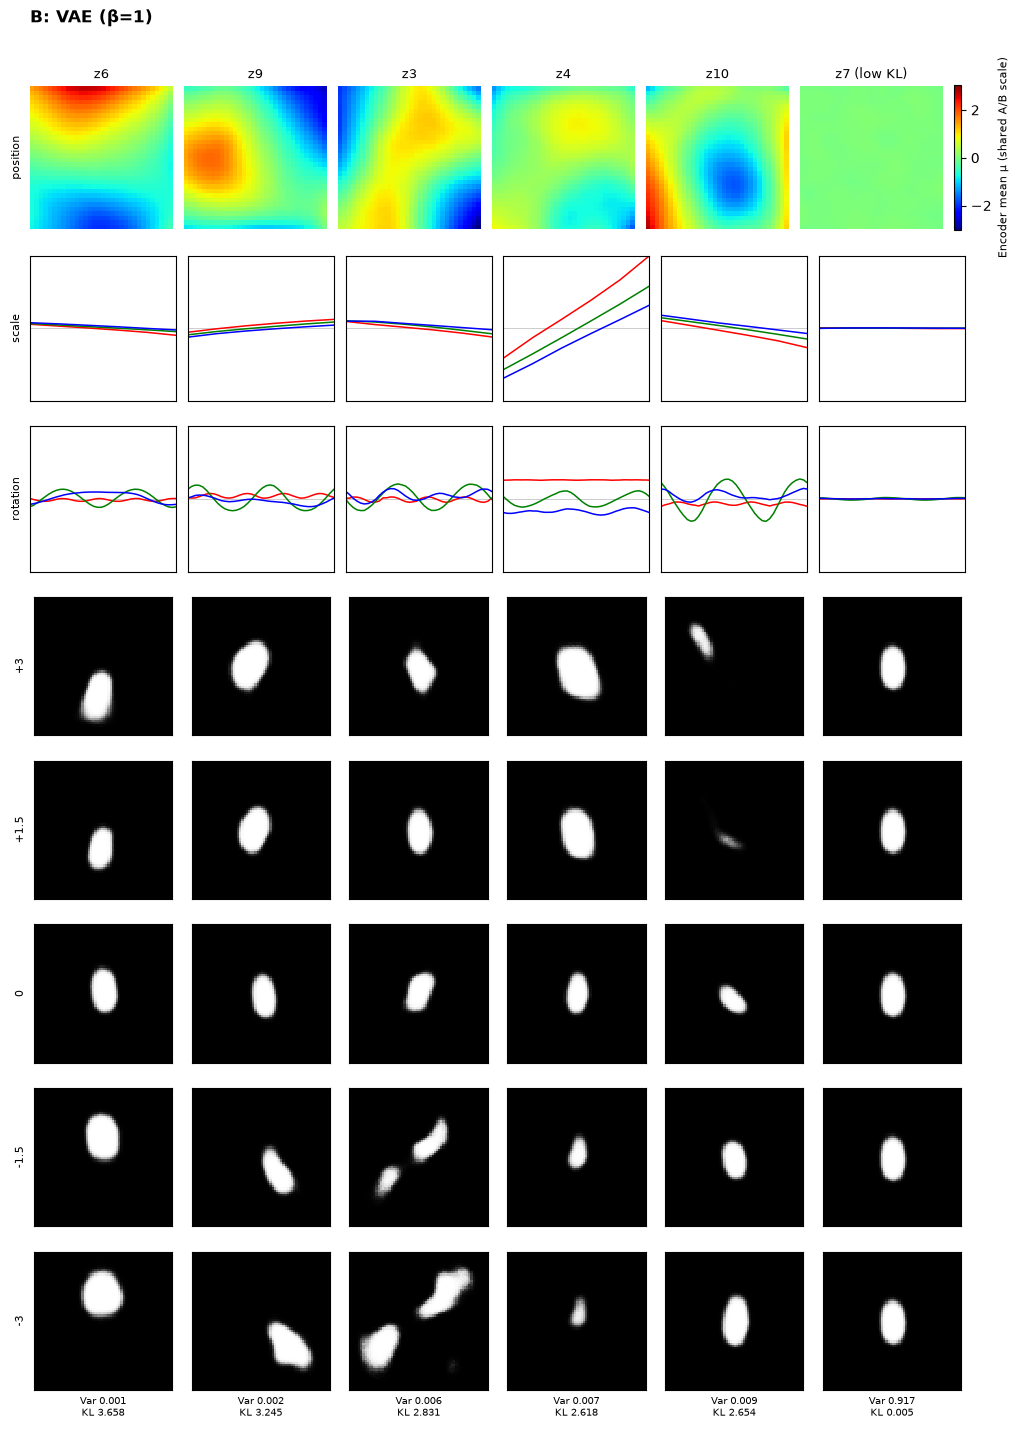

Figure 7B: β=1, seed=42, 30,000 steps; columns z: [6, 9, 3, 4, 10, 7]
Recon BCE/image: 61.532 | KL/image: 17.414

7A / β=4: active KL dimensions (>0.1) = 4; total KL = 9.581
  z9: KL 3.185; signals {'position_x': 0.981, 'position_y': 0.014, 'scale': 0.0, 'rotation': 0.005}
  z6: KL 2.804; signals {'position_x': 0.039, 'position_y': 0.882, 'scale': 0.077, 'rotation': 0.002}
  z3: KL 2.676; signals {'position_x': 0.164, 'position_y': 0.728, 'scale': 0.107, 'rotation': 0.001}
  z8: KL 0.915; signals {'position_x': 0.006, 'position_y': 0.007, 'scale': 0.0, 'rotation': 0.987}
  z10: KL 0.000; signals {'position_x': 0.295, 'position_y': 0.511, 'scale': 0.045, 'rotation': 0.149}
  z5: KL 0.001; signals {'position_x': 0.245, 'position_y': 0.547, 'scale': 0.097, 'rotation': 0.111}

7B / β=1: active KL dimensions (>0.1) = 6; total KL = 17.370
  z6: KL 3.658; signals {'position_x': 0.032, 'position_y': 0.95, 'scale': 0.005, 'rotation': 0.013}
  z9: KL 3.245; signals {'position_x': 0.656, 'positio

In [3]:
show_panel(B, 'B')
print('Figure 7B: β=1, seed=42, 30,000 steps; columns z:', [j+1 for j in B['selected']])
print('Recon BCE/image:', round(B['diagnostics']['bce_per_image'], 3),
      '| KL/image:', round(B['diagnostics']['kl_per_image'], 3))

# These ratios are descriptive main-effect response signals, NOT the paper's
# classification-based disentanglement metric. Shape and interactions are omitted.
for label, panel in (('7A / β=4', A), ('7B / β=1', B)):
    r = report(panel, LIMITS)
    kl = np.array(r['mean_kl_all_10'])
    frac = r['factor_response_diagnostics']['within_4_factor_signal_fractions']
    print(f'\n{label}: active KL dimensions (>0.1) = {(kl > 0.1).sum()}; total KL = {kl.sum():.3f}')
    for j in panel['selected']:
        dominant = {factor: round(float(arr[j]), 3) for factor, arr in frac.items()}
        print(f'  z{j+1}: KL {kl[j]:.3f}; signals {dominant}')